SITUACIÓN 1: DESEMPEÑO COMERCIAL

In [2]:
#cantidad de filas y columnas del dataset
import pandas as pd
df= pd.read_csv("dataset_peliculas_videojuegos.csv")
df.shape

(659, 17)

In [ ]:
#Para obtener los nombres de las columnas y cantidad de no nulos en cada una
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 659 entries, 0 to 658
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   659 non-null    int64  
 1   titulo               659 non-null    object 
 2   titulo_original      659 non-null    object 
 3   estreno              659 non-null    object 
 4   presupuesto_usd      659 non-null    int64  
 5   recaudacion_usd      659 non-null    int64  
 6   popularidad          659 non-null    float64
 7   nota_promedio        659 non-null    float64
 8   votos                659 non-null    int64  
 9   duracion_min         659 non-null    int64  
 10  generos              659 non-null    object 
 11  categoria            659 non-null    object 
 12  anio                 659 non-null    int64  
 13  ROI                  142 non-null    float64
 14  ganancia_bruta_usd   142 non-null    float64
 15  ranking_recaudacion  659 non-null    int

In [ ]:
#Cantidad de nulos de las columnas ROI y ganancia bruta
#nulos_ROI=df["ROI"].isnull().sum()
#print(nulos_ROI)
nulos_ganancia_bruta= df["ganancia_bruta_usd"].isnull().sum()
print(nulos_ganancia_bruta)

517


In [ ]:
#Comprobando algunos valores nulos
df.tail(10)

,id,titulo,titulo_original,estreno,presupuesto_usd,recaudacion_usd,popularidad,nota_promedio,votos,duracion_min,generos,categoria,anio,ROI,ganancia_bruta_usd,ranking_recaudacion,fecha_extraccion
649,1518841,Violent Volition,Violent Volition,2025-07-12,0,0,1.1813,0.000,0,5,"Animación, Ciencia ficción",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
650,1383636,Askepote,Askepote,2025-04-18,0,0,1.3191,7.800,4,80,"Animación, Familia",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
651,1418665,Fushigi ‌no ‌Kuni ‌de ‌Alice to -Dive ‌in ‌Won...,不思議の国でアリスと –Dive in Wonderland–,2025-08-29,0,0,1.4498,7.700,6,95,"Animación, Aventura, Fantasía, Familia",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
652,1414334,Feasting Junta,Feasting Junta,2025-01-24,0,0,1.1936,0.000,0,0,Animación,Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
653,1575946,All Heart,All Heart,2025-12-06,0,0,0.9861,3.000,1,9,"Animación, Drama",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
654,1542697,Cirkusrevyen 2025,Cirkusrevyen 2025,2025-09-07,0,0,1.2196,6.700,3,0,"Comedia, Familia",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
655,1306284,Wolfgang (Extraordinario),Wolfgang (Extraordinari),2025-03-14,0,0,1.2869,6.655,58,110,"Familia, Drama, Música",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
656,1639279,El explorador,El explorador,2025-10-01,4600,0,1.5117,0.000,0,0,"Animación, Fantasía, Drama",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
657,1573375,Wasiat Warisan,Wasiat Warisan,2025-12-04,0,0,1.2750,6.500,2,116,"Drama, Familia",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10
658,1248732,Семьянин,Семьянин,2025-12-04,0,0,1.4334,5.800,5,98,"Comedia, Familia",Familiar/Animacion 2025,2025,NaN,NaN,227,2026-11-10


In [ ]:
#Revisión de tipos de categoría
df["categoria"].value_counts()

categoria
Adaptacion videojuego                                          459
Familiar/Animacion 2025                                        199
Adaptacion videojuego | Familiar/Animacion 2025 | Minecraft      1
Name: count, dtype: int64

In [ ]:
#Obtener porcentaje de peliculas 2025 que superaron el promedio en presupuesto 
#Realizo el filtro de peliculas y adaptaciones que no tengan valor de 0 en el presupuesto y que sean del 2025
df_filtro1 = df[(df["presupuesto_usd"]>0)&((df["estreno"]>='2025-01-01')&(df["estreno"]<='2025-12-01'))]
#df_filtro1
promedio_presupuesto = df_filtro1["presupuesto_usd"].mean()
print((promedio_presupuesto).round(2))

38258055.49


In [12]:
#cuantas peliculas están por encima del presupuesto promedio
df_pres_may_prom = df_filtro1[df_filtro1["presupuesto_usd"]>promedio_presupuesto]
#df_pres_may_prom["titulo"].count()
#Nombre de los titulos que superan el promedio de presupuesto invertido
#df_pres_may_prom["titulo"].value_counts()
#Lista de titulos ordenados de mayor a menor según la inversión
df_pres_may_prom.sort_values("presupuesto_usd", ascending=False)[["titulo", "recaudacion_usd", "presupuesto_usd"]]


,titulo,recaudacion_usd,presupuesto_usd
37,Blancanieves,205679463,271600000
9,Cómo entrenar a tu dragón,636596299,150000000
6,Una película de Minecraft,960387780,150000000
46,Elio,154291182,150000000
1,Zootrópolis 2,1868208796,150000000
107,Las guerreras k-pop,24619953,100000000
3,Lilo y Stitch,1038027526,100000000
0,Ne Zha 2,2270700370,80000000
33,Los tipos malos 2,239676236,80000000
55,Pitufos,124157356,58000000


In [9]:
#Se filtra el dataset de presupuesto!=0 y año 2025 pero donde la recaudacion sea mayor a 0
df_pres_recau=df_filtro1[df_filtro1["recaudacion_usd"]>0]
# Se obtiene el promedio de lo recaudado
recaudacion_prom=df_pres_recau["recaudacion_usd"].mean()
print((recaudacion_prom).round(2))

274089533.76


In [13]:
#Se establecen los productos que recaudaron más que el valor promedio
df_recau_mayor_prom = df_pres_recau[df_pres_recau["recaudacion_usd"]>recaudacion_prom]
#Nombre de los titulos que superan el promedio de lo recaudado
#df_recau_mayor_prom.value_counts()
#Lista de titulos de films ordenados de mayor a menor en cuanto a la recaudación total
df_recau_mayor_prom.sort_values("recaudacion_usd", ascending=False)[["titulo", "recaudacion_usd", "presupuesto_usd"]]

,titulo,recaudacion_usd,presupuesto_usd
0,Ne Zha 2,2270700370,80000000
1,Zootrópolis 2,1868208796,150000000
3,Lilo y Stitch,1038027526,100000000
6,Una película de Minecraft,960387780,150000000
8,Guardianes de la noche: Kimetsu no Yaiba La fo...,793594078,20000000
9,Cómo entrenar a tu dragón,636596299,150000000


In [16]:
#Se incorporan los 3 filtros: recaudacion, presupuesto y fechas de estreno en el año 2025
df_2025 = df[(df["presupuesto_usd"] > 0) & (df["recaudacion_usd"] > 0) & (df["estreno"] >= "2025-01-01") & (df["estreno"] < "2026-01-01")].copy()

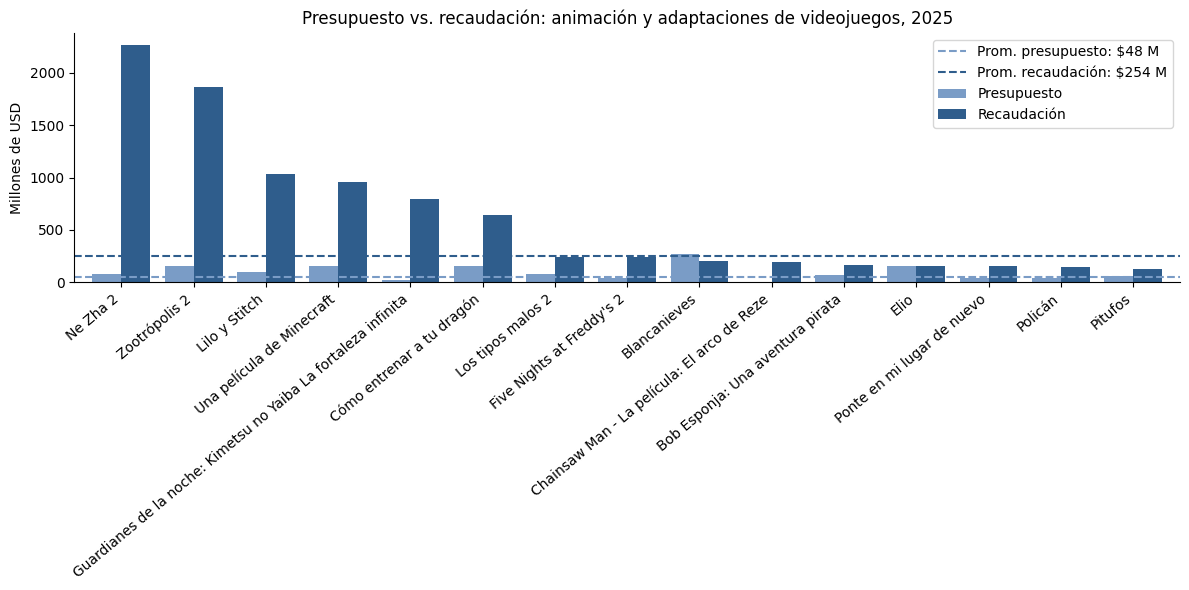

In [ ]:
#INSIGTH diapositiva
#top 5: “4 de las 5 películas más taquilleras de 2025 también superaron el presupuesto promedio.”
#(Debajo del gráfico):
#“Las películas más taquilleras de 2025 en animación y videojuegos,
# casi todas con inversión superior al promedio,
# aunque no toda gran inversión se tradujo en éxito (Blancanieves, Elio).”
# Grafico de barras apiladas de presupuesto y recaudacion
import matplotlib.pyplot as plt

# Variables segun las columnas
col_titulo = "titulo"
col_pre = "presupuesto_usd"
col_rec = "recaudacion_usd"

# Promedios
prom_pre = df_2025[col_pre].mean() / 1e6
prom_rec = df_2025[col_rec].mean() / 1e6

# Ordenar por recaudación y pasar a millones de dólares
d = df_2025.sort_values(col_rec, ascending=False).head(15).copy()
d["Presupuesto"] = d[col_pre] / 1e6
d["Recaudación"] = d[col_rec] / 1e6


# Barras agrupadas (pandas las ubica solo, sin calcular posiciones)
ax = d.set_index(col_titulo)[["Presupuesto", "Recaudación"]].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#7A9CC6", "#2F5D8C"],
    width=0.8,
)

# Líneas de promedio
ax.axhline(prom_pre, color="#7A9CC6", linestyle="--", linewidth=1.5,
           label=f"Prom. presupuesto: ${prom_pre:,.0f} M")
ax.axhline(prom_rec, color="#2F5D8C", linestyle="--", linewidth=1.5,
           label=f"Prom. recaudación: ${prom_rec:,.0f} M")

ax.set_xlabel("")
ax.set_ylabel("Millones de USD")
ax.set_title("Presupuesto vs. recaudación: animación y adaptaciones de videojuegos, 2025")
ax.set_xticklabels(d[col_titulo], rotation=40, ha="right")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("grafico_presupuesto_recaudacion.png", dpi=200)
plt.show()


Análisis del ROI

In [18]:
df_2025["ROI"].isnull().sum()

np.int64(0)

In [20]:
promedio_ROI = df_2025["ROI"].mean()
print(promedio_ROI)

6.433363953914979


In [21]:
mediana_ROI= df_2025["ROI"].median()
print(mediana_ROI)

2.614567875


In [28]:
peliculas_mas_roi= df_2025[df_2025["ROI"]>mediana_ROI]
grupo_ordenado = peliculas_mas_roi[["titulo", "ROI"]].sort_values("ROI",ascending=False)
print(grupo_ordenado)


                                                titulo        ROI
40         Chainsaw Man - La película: El arco de Reze  46.682927
8    Guardianes de la noche: Kimetsu no Yaiba La fo...  39.679704
87                                              Exit 8  31.351914
0                                             Ne Zha 2  28.383755
1                                        Zootrópolis 2  12.454725
3                                        Lilo y Stitch  10.380275
133               Ratones al ataque: Operación Navidad   8.278708
95                                      ಮಹಾವತಾರ ನರಸಿಂಹ   7.659574
34                           Five Nights at Freddy's 2   6.654691
6                            Una película de Minecraft   6.402585
89   El Mago de Ciudad Esmeralda: El Camino de Bald...   4.642243
9                            Cómo entrenar a tu dragón   4.243975
122                               Papa Zola: The Movie   4.027681
47                          Ponte en mi lugar de nuevo   3.647070
49        

In [ ]:
#INSIGTH DIAPOSITIVA
#la mitad de las películas recaudó más de 2,6 veces su inversión, 
# pero la diferencia entre el promedio y la mediana
# muestra que el éxito está muy concentrado en pocos títulos.
#Unas pocas películas con retornos enormes inflan el promedio:

#Chainsaw Man: La película, ROI de 46,7.
#Kimetsu no Yaiba: La fortaleza infinita, ROI de 39,7.
#Exit 8, ROI de 31,4.
#Ne Zha 2, ROI de 28,4.

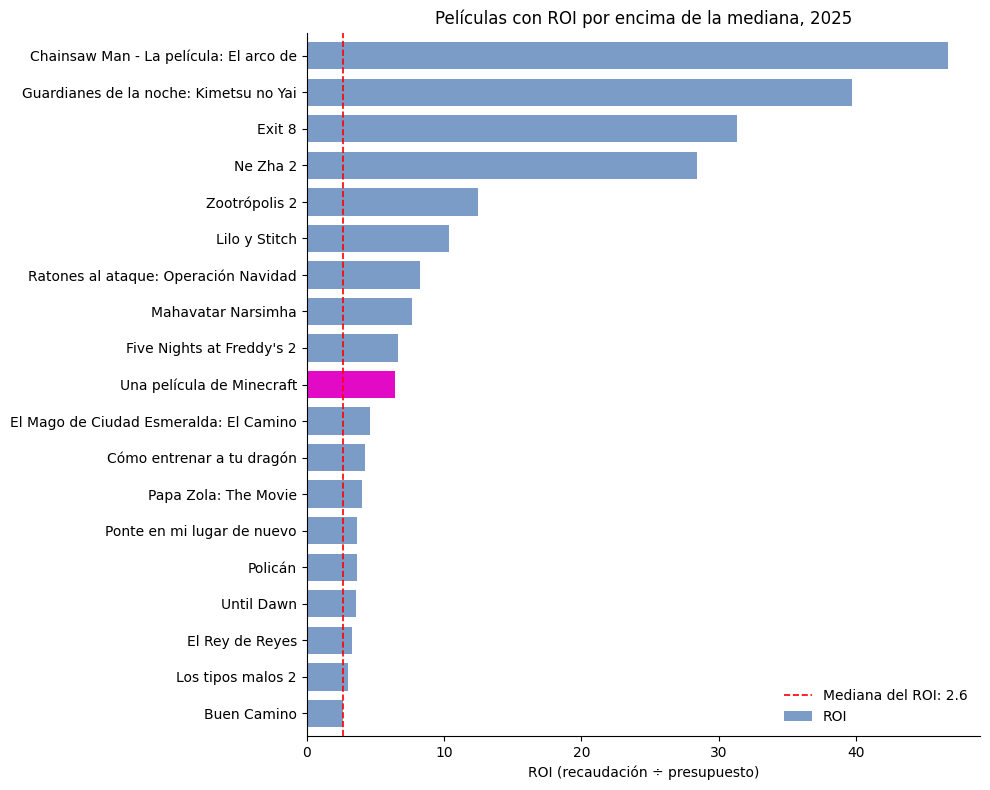

In [31]:
#Grafico
import matplotlib.pyplot as plt
# Películas por encima de la mediana, de menor a mayor
g = df_2025[df_2025["ROI"] > mediana_ROI][["titulo", "ROI"]].sort_values("ROI", ascending=True)
g["titulo_corto"] = g["titulo"].replace({"ಮಹಾವತಾರ ನರಸಿಂಹ": "Mahavatar Narsimha"}).str.slice(0, 38)

# Naranja para Minecraft, azul para el resto
colores = ["#E30AC6" if t == "Una película de Minecraft" else "#7A9CC6" for t in g["titulo"]]

ax = g.plot(kind="barh", x="titulo_corto", y="ROI", color=colores,
            legend=False, figsize=(10, 8), width=0.75)

ax.axvline(mediana_ROI, color="red", linestyle="--", linewidth=1.2,
           label=f"Mediana del ROI: {mediana_ROI:.1f}")
ax.legend(loc="lower right", frameon=False)

ax.set_xlabel("ROI (recaudación ÷ presupuesto)")
ax.set_ylabel("")
ax.set_title("Películas con ROI por encima de la mediana, 2025")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("grafico_roi.png", dpi=200)
plt.show()